In [19]:
# ============================================================
# DIABLO Model for Cross-Omic Correlation Structure
# (methylation + expression, design favoring inter-block correlation)
# ============================================================

if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

# print mixomics version
packageVersion("mixOmics")

[1] ‘6.26.0’

In [20]:
# Read in configs/class_colors.tsv
COLORS_PATH = "/home/mariya/Development/pallas/configs/class_colors.tsv"
CLASS_COLORS <- read.table(COLORS_PATH,
                           sep = "\t",
                           header = FALSE,
                           col.names = c("class", "color"),
                           comment.char = "",
                           stringsAsFactors = FALSE)
CLASS_COLORS

class,color
<chr>,<chr>
"AML, KMT2A-r",#2ED9FF
"AML, RUNX1::RUNX1T1",#F8A19F
"AML, CBFB::MYH11",#FEAF16
"AML, NPM1alt",#FA0087
"AML, NUP98-r",#D85FF7
"AML, CEBPAalt",#F7E1A0
"AML, CBFA2T3::GLIS2",#7ED7D1
"AML, DEK::NUP214",#85660D
"AML, APL-PML::RARA",#BDCDFF


In [21]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets/labeled-diagnostic-bimodal-reduced")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")
OUTPUT_DIR <- file.path(DATA_DIR, "mixOmics/correlation")

if (!dir.exists(OUTPUT_DIR)) {
    dir.create(OUTPUT_DIR, recursive = TRUE)
}

In [22]:
source("helpers.R")
train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 1227 
GEX features: 1121 
DNAm features: 1186 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [23]:

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------
# X should be a named list of matrices: samples (rows) x features (columns)
# Both blocks must have the SAME samples in the SAME order

X <- list(
  methylation = train_data$X_dnam,   # replace with your methylation matrix
  expression  = train_data$X_gex    # replace with your expression matrix
)

Y <- train_data$Y   # factor vector of class labels, same sample order as X

# sanity check: sample order must match across blocks and Y
stopifnot(all(rownames(X$methylation) == rownames(X$expression)))
stopifnot(length(Y) == nrow(X$methylation))

head(X$methylation)
head(X$expression)
head(Y)


,cg10443049,cg07275648,cg00760938,cg04646674,cg12183594,cg03732020,cg14992144,cg13799263,cg08166720,cg00015639,⋯,cg01955153,cg26092233,cg18631798,cg21927946,cg11551919,cg01883662,cg20294319,cg12737392,cg09291834,cg11414821
ALL_1000,0.8325,0.9452,0.0400,0.9366,0.9854,0.7879,0.0186,0.9181,0.9419,0.2988,⋯,0.1614,0.0677,0.0333,0.2134,0.9773,0.9641,0.0702,0.0862,0.8104,0.0315
ALL_1003,0.9219,0.6754,0.1550,0.9236,0.9849,0.9087,0.0272,0.7213,0.9059,0.7597,⋯,0.0889,0.1056,0.0643,0.7567,0.9731,0.9196,0.0946,0.0913,0.0193,0.0256
ALL_1005,0.9113,0.9435,0.0375,0.6264,0.9850,0.9844,0.0230,0.7807,0.9334,0.9095,⋯,0.2638,0.0489,0.0296,0.0678,0.9645,0.9251,0.0899,0.1216,0.4870,0.0326
ALL_1019,0.7243,0.9433,0.0757,0.9088,0.9829,0.9830,0.0267,0.8941,0.4691,0.6096,⋯,0.1940,0.0529,0.0354,0.0220,0.3327,0.1337,0.0656,0.0774,0.1054,0.0233
ALL_1023,0.8656,0.9308,0.1669,0.8532,0.9857,0.8091,0.0480,0.9283,0.9532,0.8493,⋯,0.2563,0.1559,0.0972,0.0441,0.9504,0.9194,0.0604,0.1027,0.1858,0.0363
ALL_1026,0.9320,0.6853,0.0826,0.8681,0.9848,0.9876,0.0354,0.9055,0.9592,0.7046,⋯,0.1624,0.1184,0.0643,0.0251,0.3294,0.1498,0.0533,0.0888,0.0324,0.0294


,ENSG00000184507,ENSG00000079102,ENSG00000248329,ENSG00000101115,ENSG00000172752,ENSG00000097007,ENSG00000132185,ENSG00000167880,ENSG00000177469,ENSG00000188064,⋯,ENSG00000170396,ENSG00000130702,ENSG00000187325,ENSG00000169213,ENSG00000186980,ENSG00000182747,ENSG00000144681,ENSG00000072954,ENSG00000181007,ENSG00000107819
ALL_1000,-1.608643,-1.608643,15.995107,4.8418488,-1.4407131,6.202016,-0.8269021,0.3324897,1.0468822,-1.306680,⋯,-0.2482395,1.155457,6.090830,-1.60864328,-1.608643,-1.6086433,-1.269090,0.7956456,2.456942,6.361923
ALL_1003,7.866846,-1.608643,-1.608643,-0.1704226,-1.6086433,6.221609,-1.6086433,-0.5538530,-0.7979199,-1.373961,⋯,-1.6086433,-1.147371,4.677110,0.26710648,-1.608643,-1.1408426,-1.608643,-1.2343983,3.309382,5.515478
ALL_1005,-1.608643,-1.608643,-1.608643,3.0300396,-1.5171299,5.962302,5.6071701,0.6443205,-0.6988636,-1.608643,⋯,-1.6086433,1.857859,6.355210,-0.24149963,-1.608643,-1.6086433,3.743243,3.2675844,3.515856,4.569093
ALL_1019,-1.608643,-1.608643,-1.608643,7.0165835,-1.6086433,5.654076,1.5010946,3.2958788,-0.2369391,-1.608643,⋯,-1.6086433,1.988980,5.567993,0.44466570,-1.608643,-1.6086433,-1.161472,3.8516648,2.002225,5.698553
ALL_1023,6.295659,-1.608643,-1.608643,4.0362302,-0.4718155,6.586559,-1.0246909,5.4514953,2.5433950,-1.608643,⋯,0.2861806,-0.133622,4.903089,1.57325962,-1.608643,-0.8427656,-1.364855,0.2819973,2.888247,4.372993
ALL_1026,-1.384271,-1.608643,7.200832,-0.3788483,-1.6086433,6.458333,0.3933072,7.1349388,-0.9366025,7.595660,⋯,-1.6086433,2.223308,5.783929,0.09725186,-1.608643,-1.6086433,-1.608643,1.1623027,2.910556,5.311609


[1] B-ALL, DUX4-r      B-ALL, PAX5alt     B-ALL, MEF2D-r     B-ALL, ZNF384-r   
[5] B-ALL, ETV6::RUNX1 B-ALL, PAX5alt    
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [24]:

# ------------------------------------------------------------
# 2. Design matrix — high value to prioritize inter-block correlation
# ------------------------------------------------------------
design.corr <- matrix(1, ncol = length(X), nrow = length(X),
                       dimnames = list(names(X), names(X)))
diag(design.corr) <- 0

design.corr  # sanity check print


,methylation,expression
methylation,0,1
expression,1,0


In [25]:
NCOMP <- 35
KEEP_X <- 100

keep_X = list(
  methylation = rep(KEEP_X, NCOMP),
  expression  = rep(KEEP_X, NCOMP)
)

# ------------------------------------------------------------
# 4. Tune keepX (features per block per component)
# ------------------------------------------------------------
# test.keepX <- list(
#   methylation = c(10, 20, 30, 50),
#   expression  = c(10, 20, 30, 50)
# )

# tune.result <- tune.block.splsda(X, Y, ncomp = ncomp, design = design.corr,
#                                   test.keepX = test.keepX,
#                                   validation = "Mfold", folds = 5, nrepeat = 10,
#                                   dist = "max.dist")

# keepX <- tune.result$choice.keepX

# ------------------------------------------------------------
# 5. Fit final DIABLO model on full dataset
# ------------------------------------------------------------
diablo.corr <- block.splsda(X, Y, ncomp = NCOMP, keepX = keep_X, design = design.corr)
diablo.corr


Design matrix has changed to include Y; each block will be
            linked to Y.




Call:
 block.splsda(X = X, Y = Y, ncomp = NCOMP, keepX = keep_X, design = design.corr) 

 sGCCA with 35 components on block 1 named methylation 
 sGCCA with 35 components on block 2 named expression 
 sGCCA with 35 components on the outcome Y

 Dimension of block 1 is  1227 1186 
 Dimension of block 2 is  1227 1121 
 Outcome Y has 25 levels 

 Selection of 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 variables on each of the sGCCA components on the block 1 
 Selection of 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 variables on each of the sGCCA components on the block 2 

 Main numerical outputs: 
 -------------------- 
 loading vectors: see object$loadings 
 variates: see object$variates 
 variable names: see object$names 

 Functions to visualise samples: 
 -------------------- 
 plotIndiv, plot

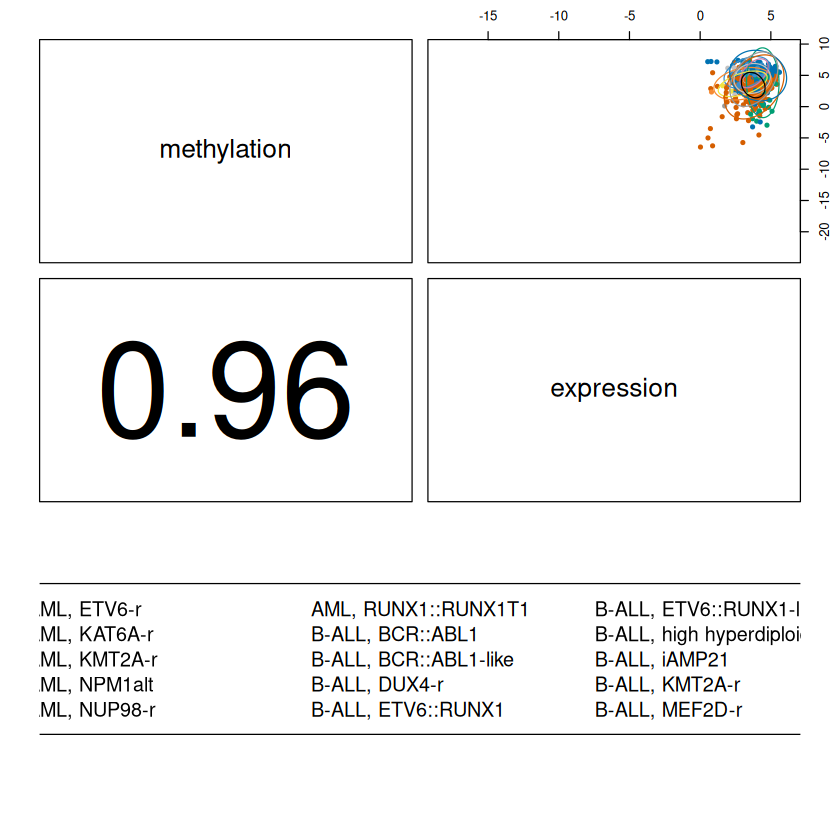

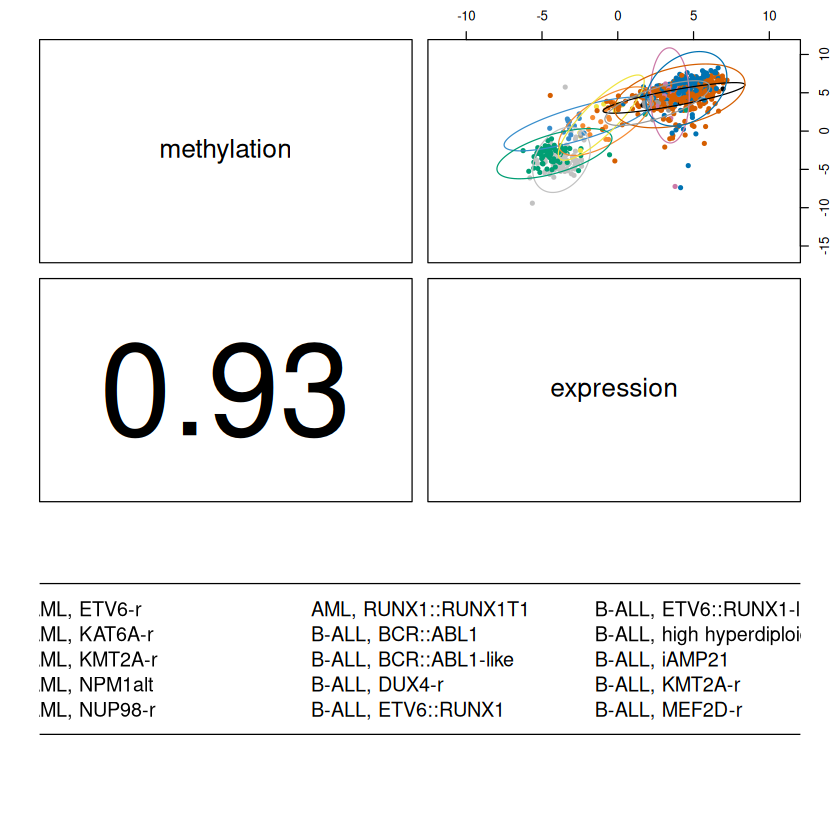

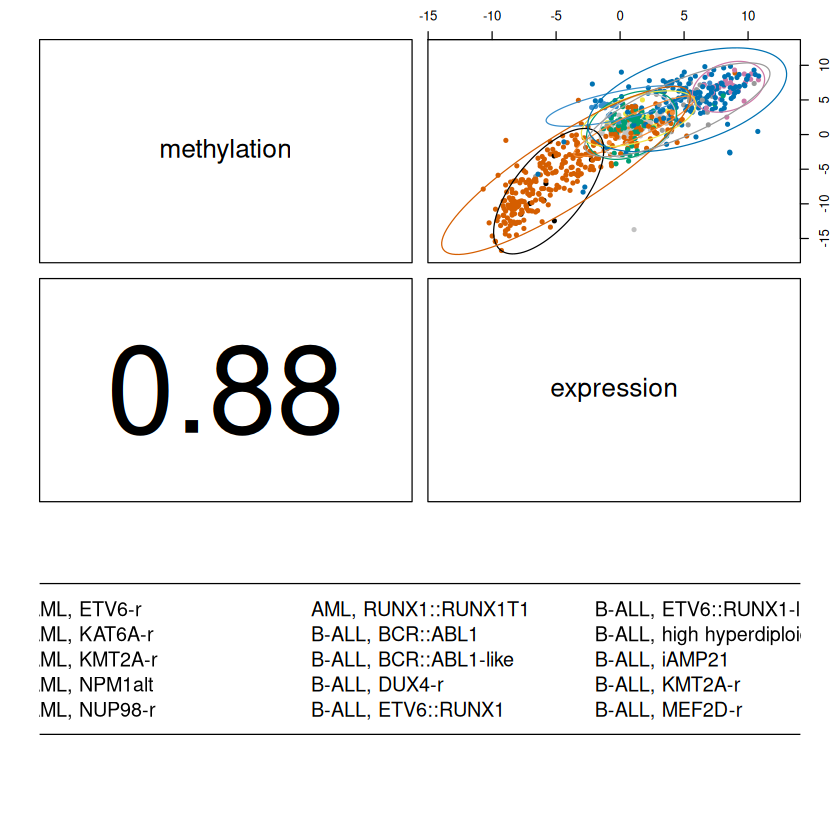

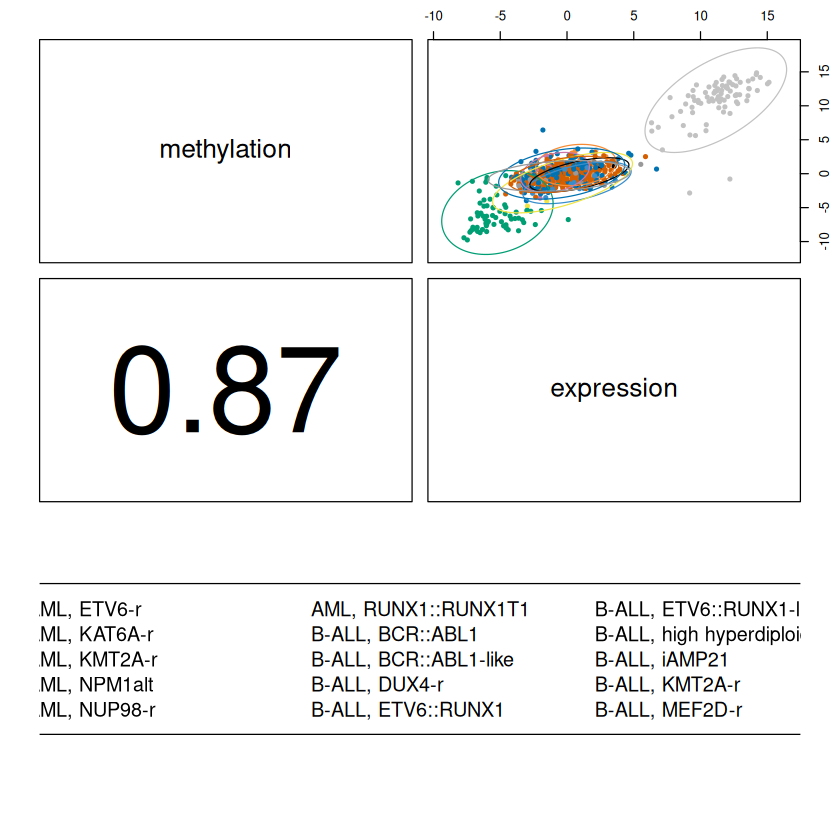

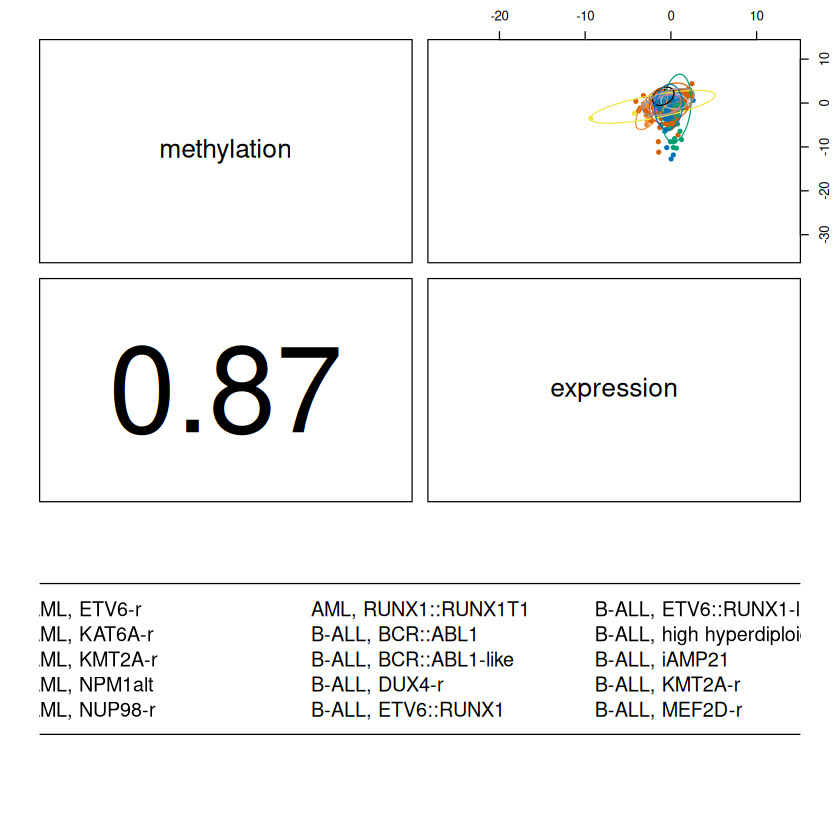

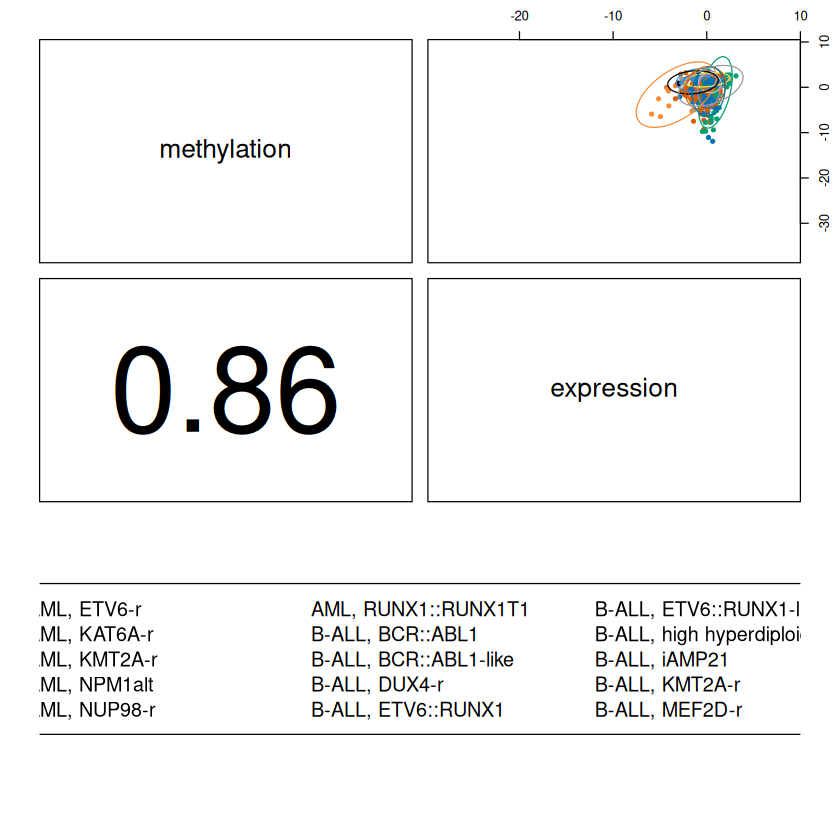

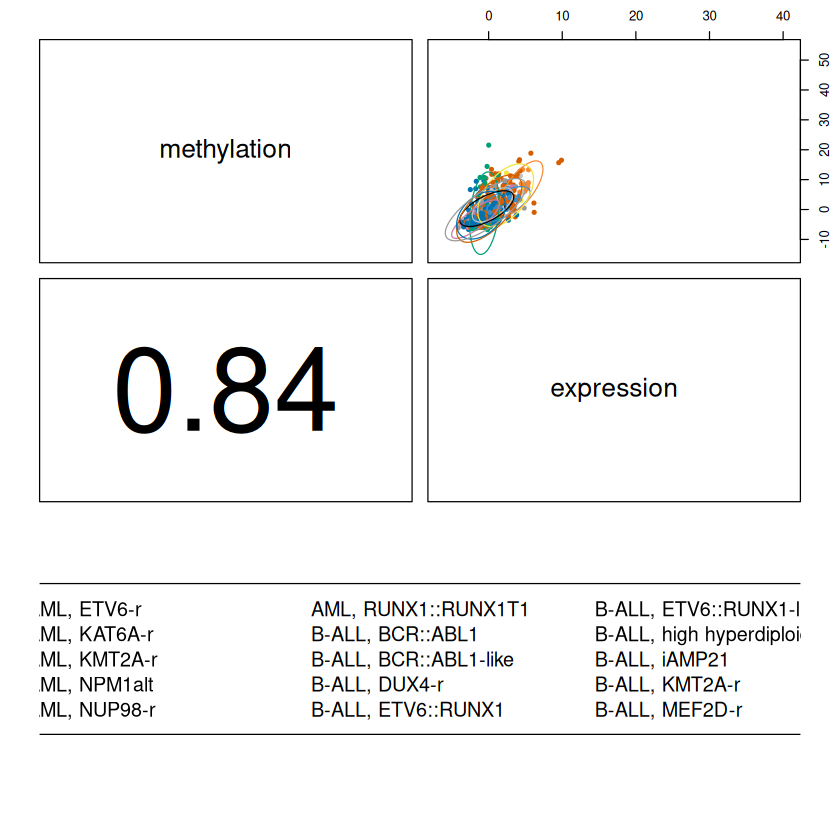

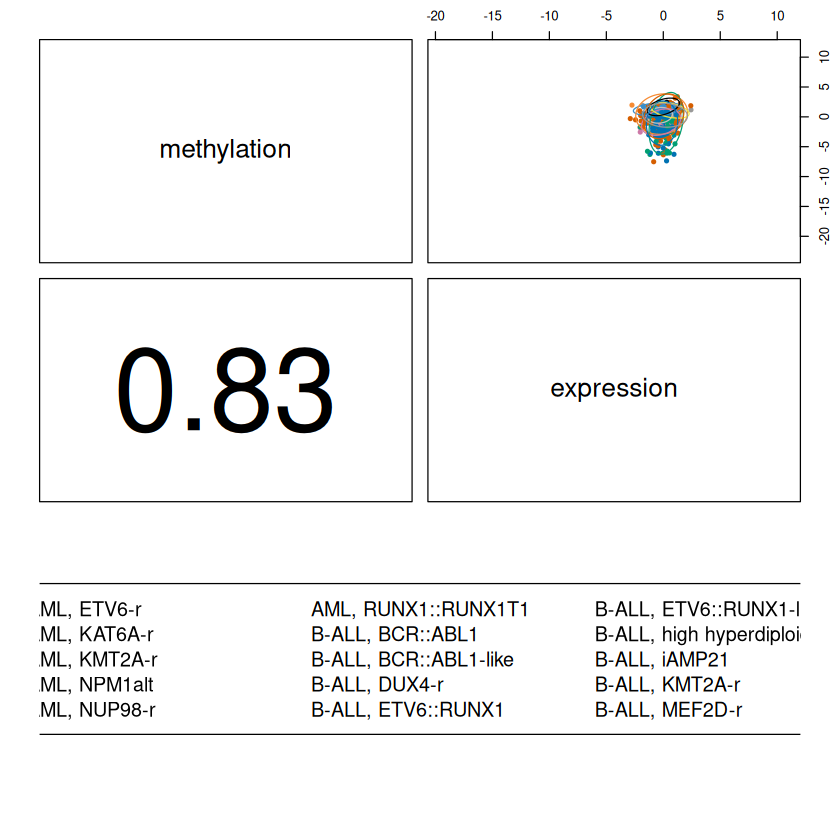

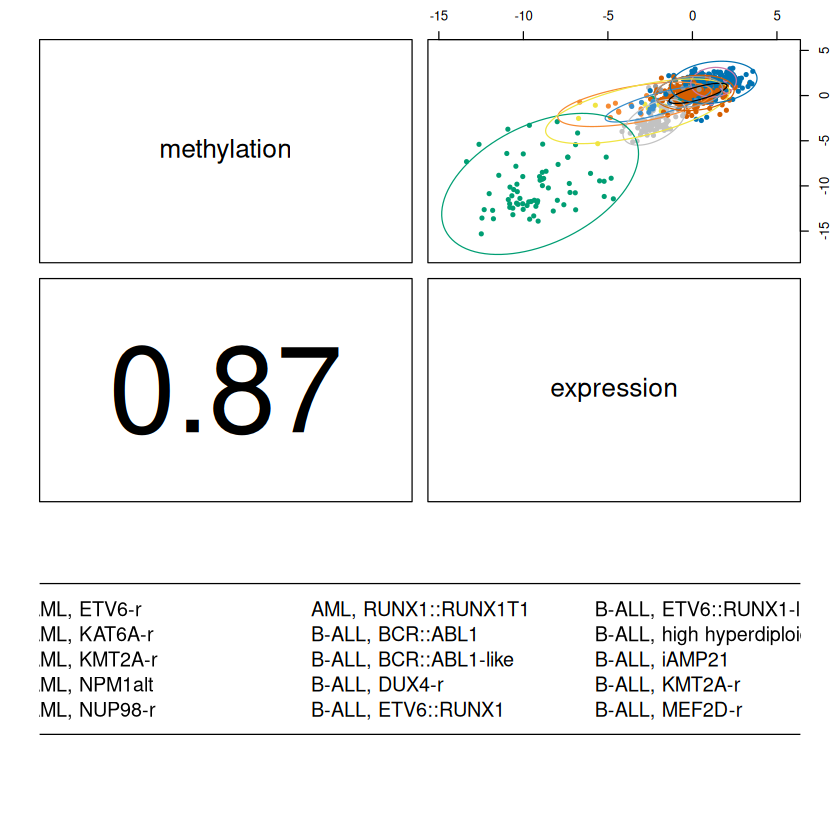

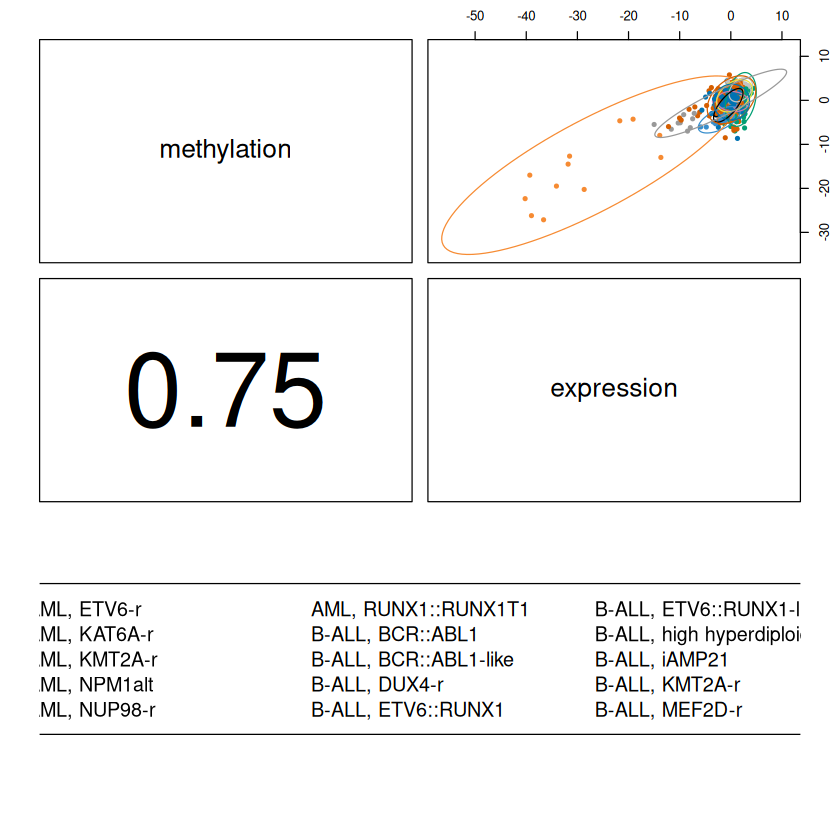

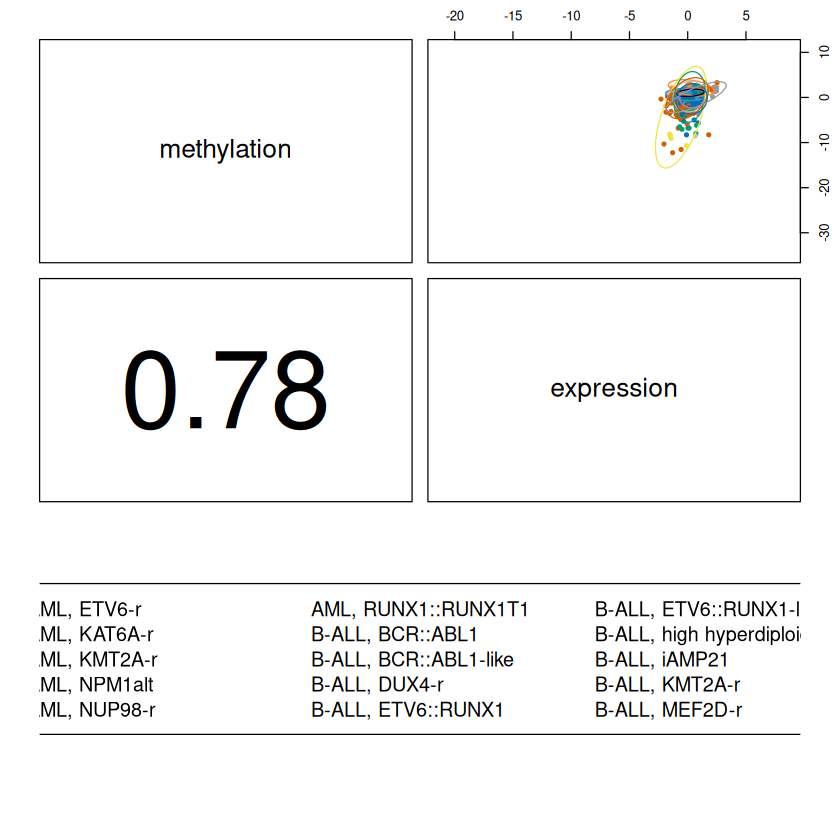

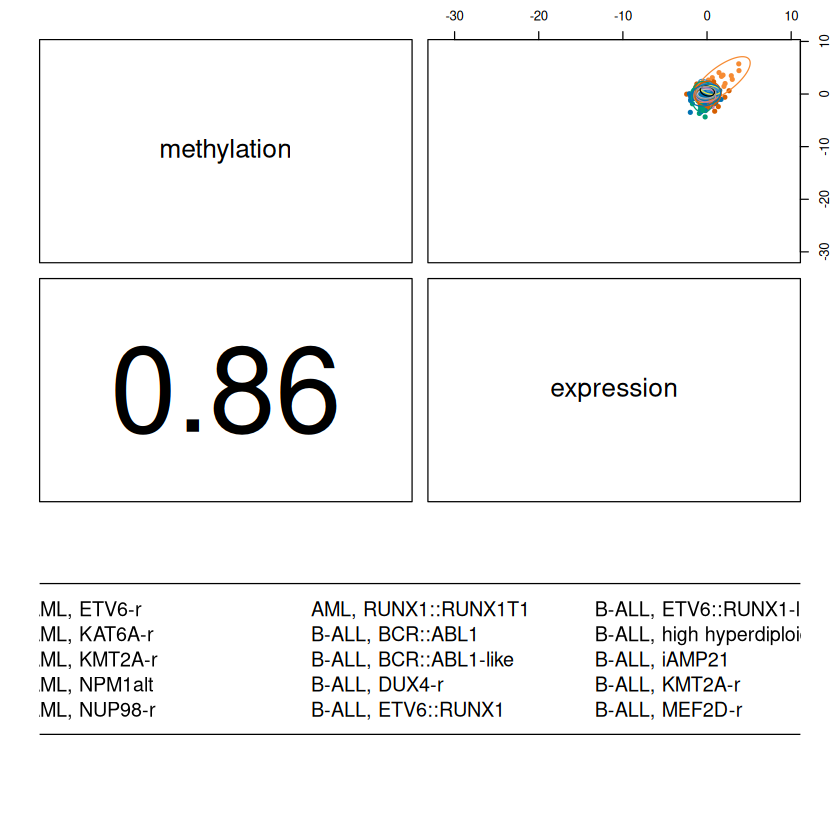

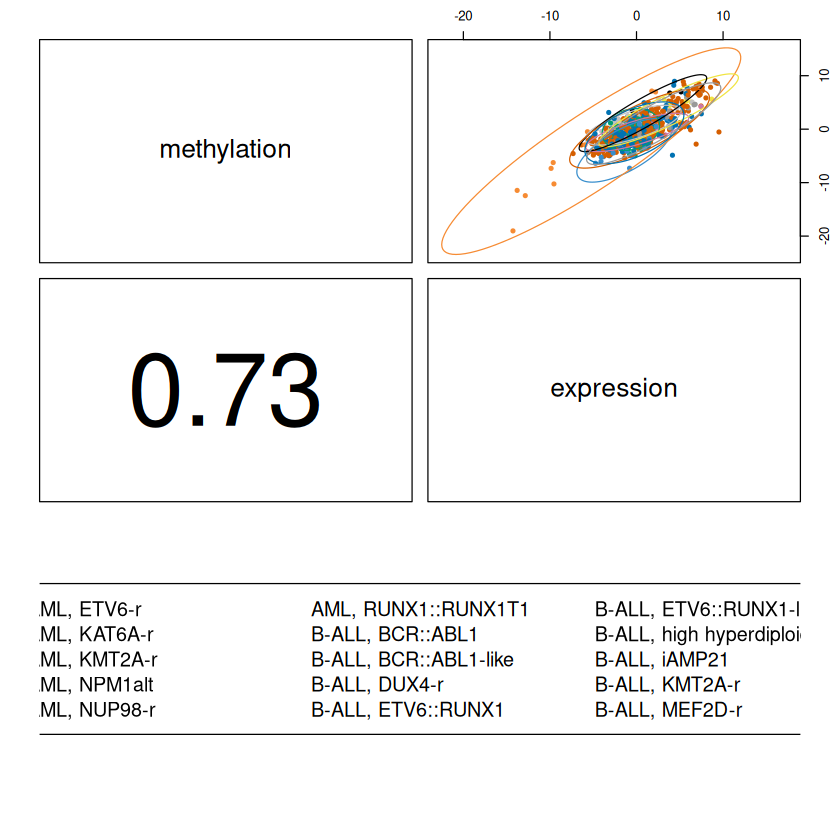

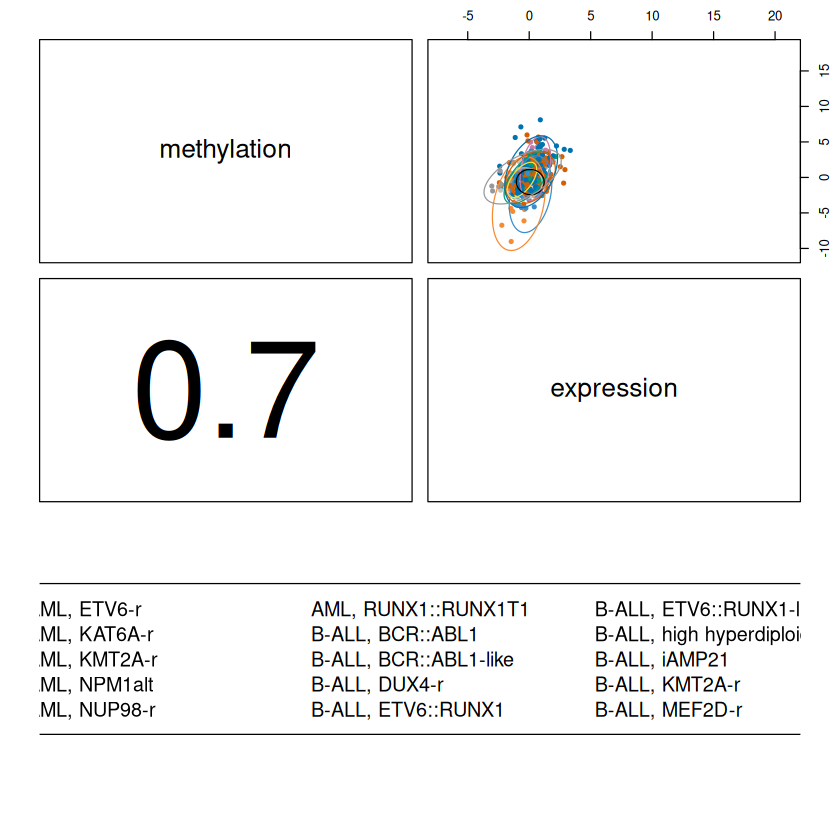

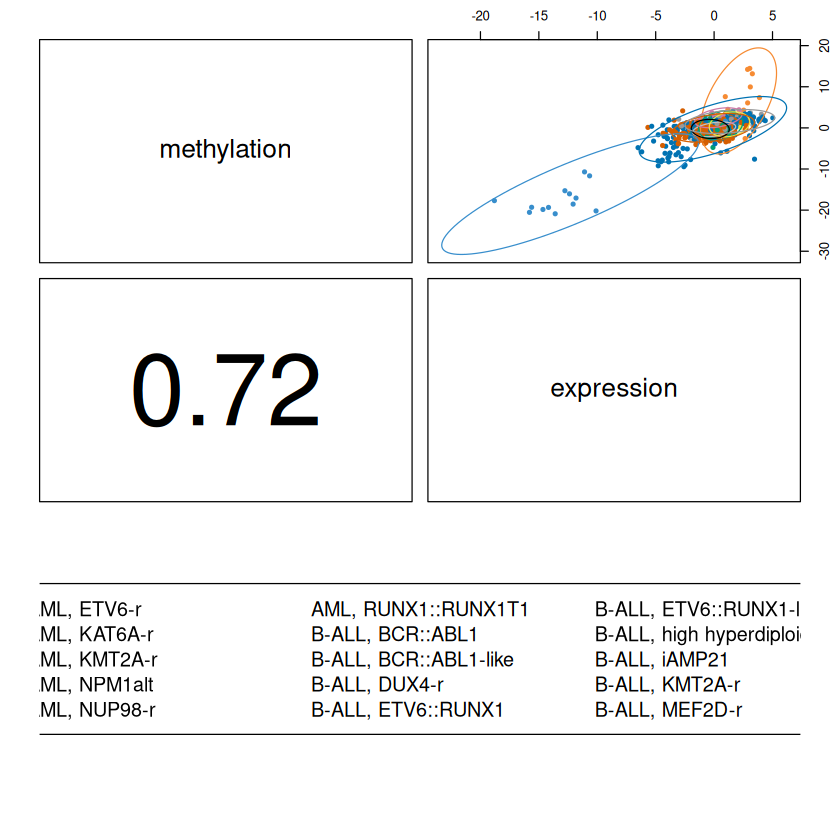

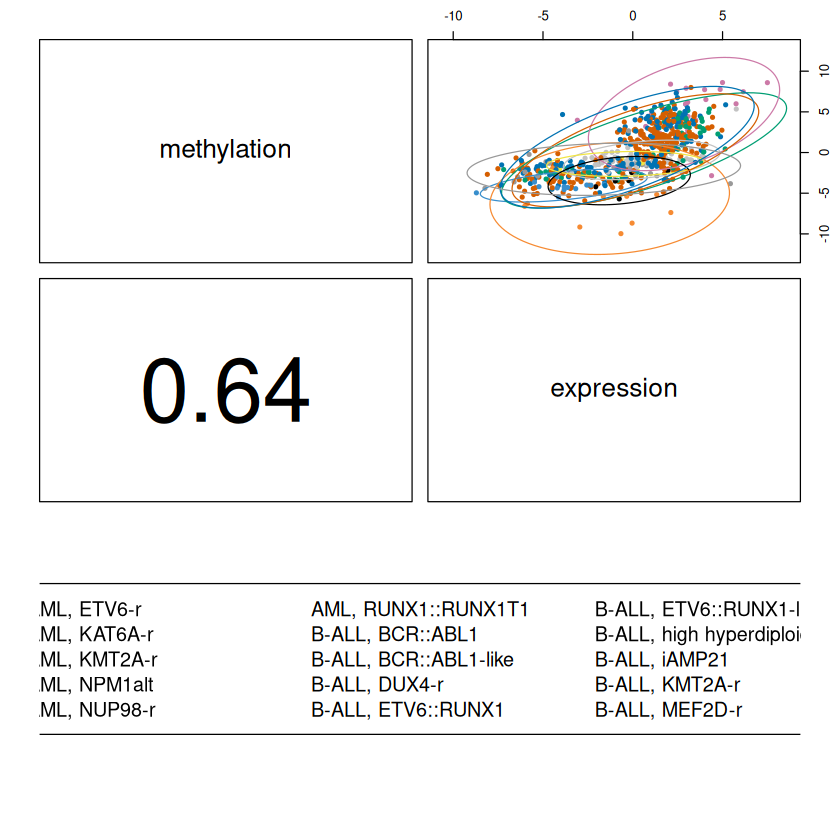

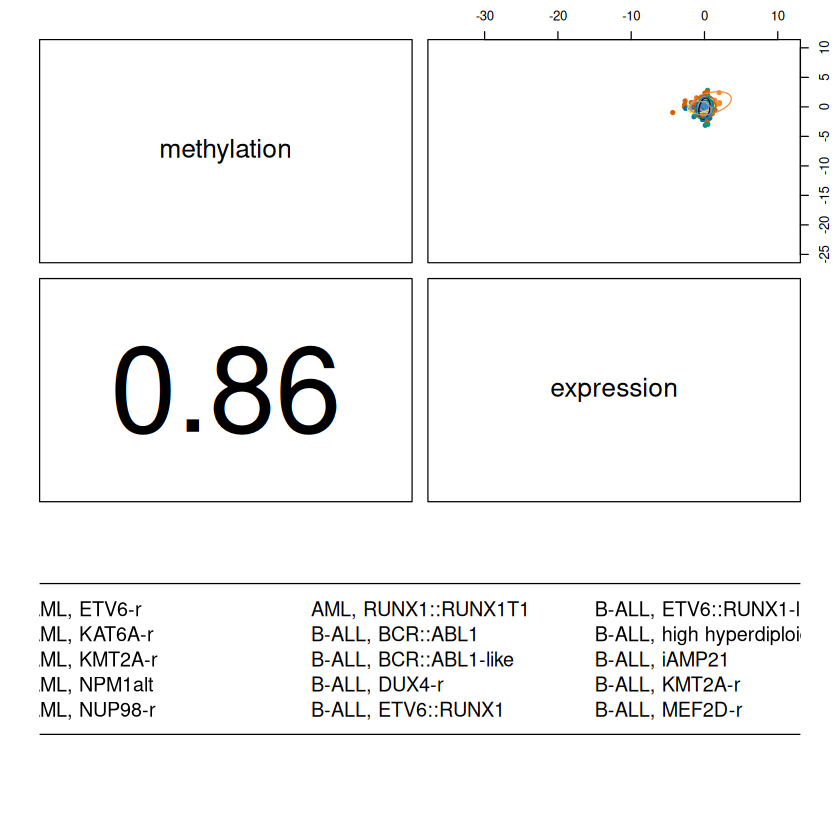

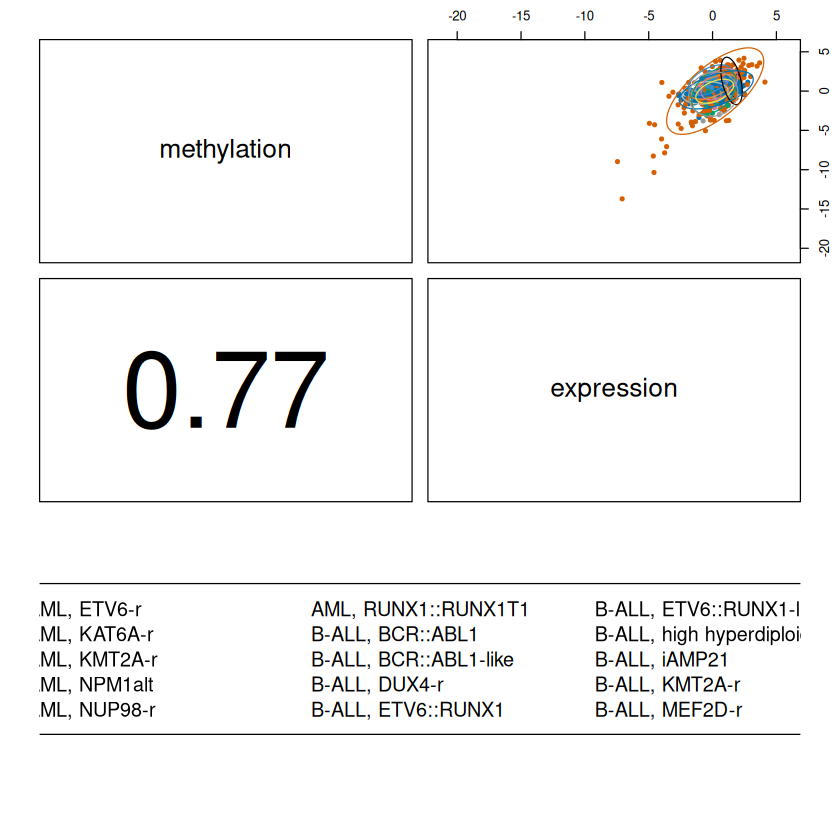

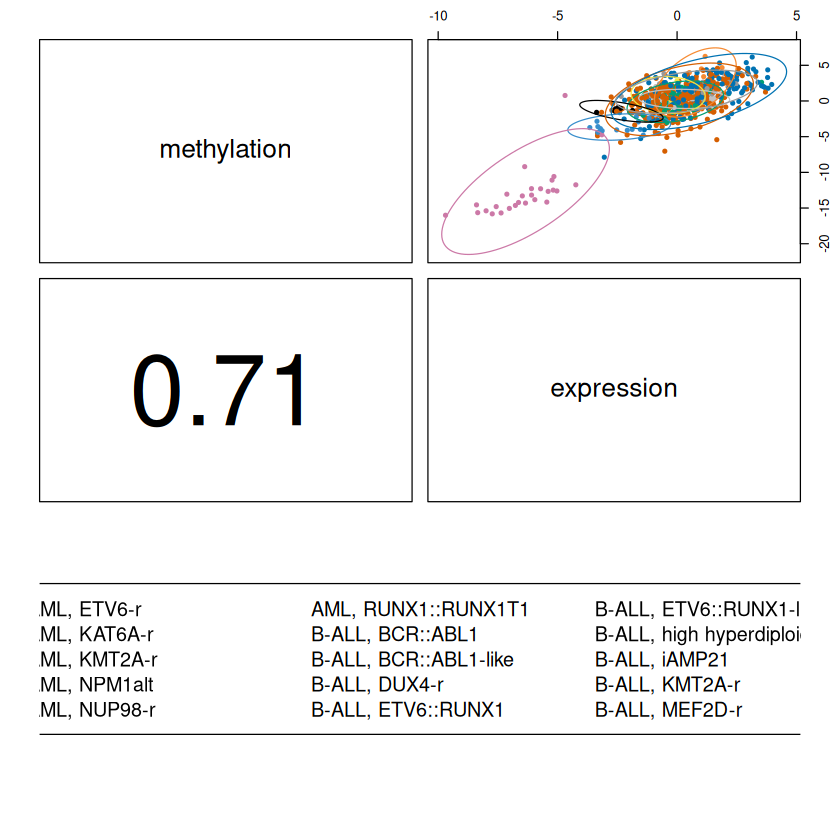

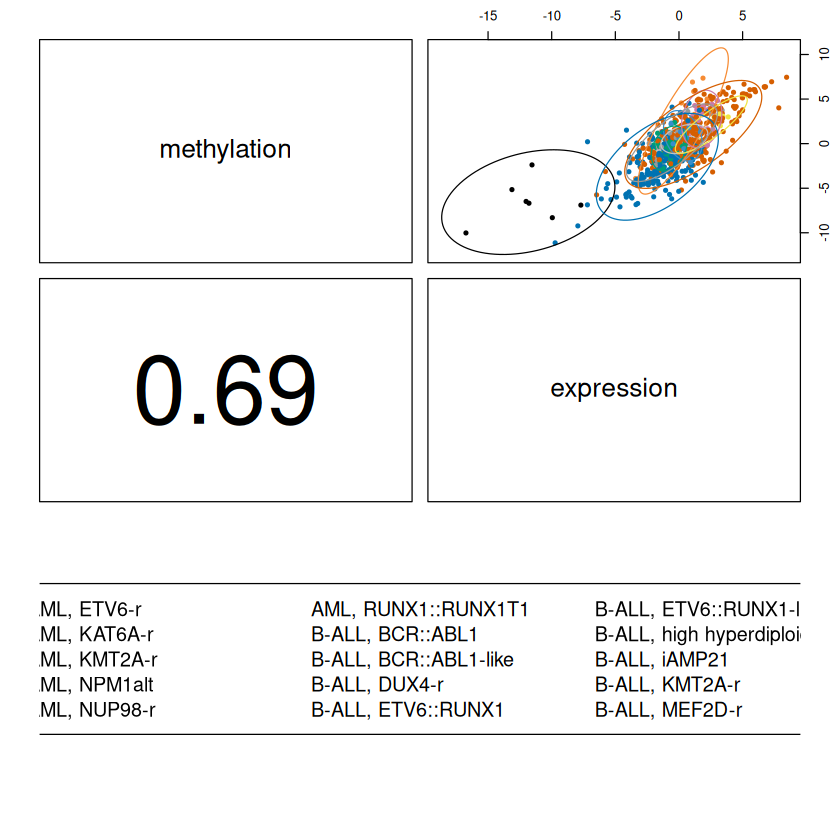

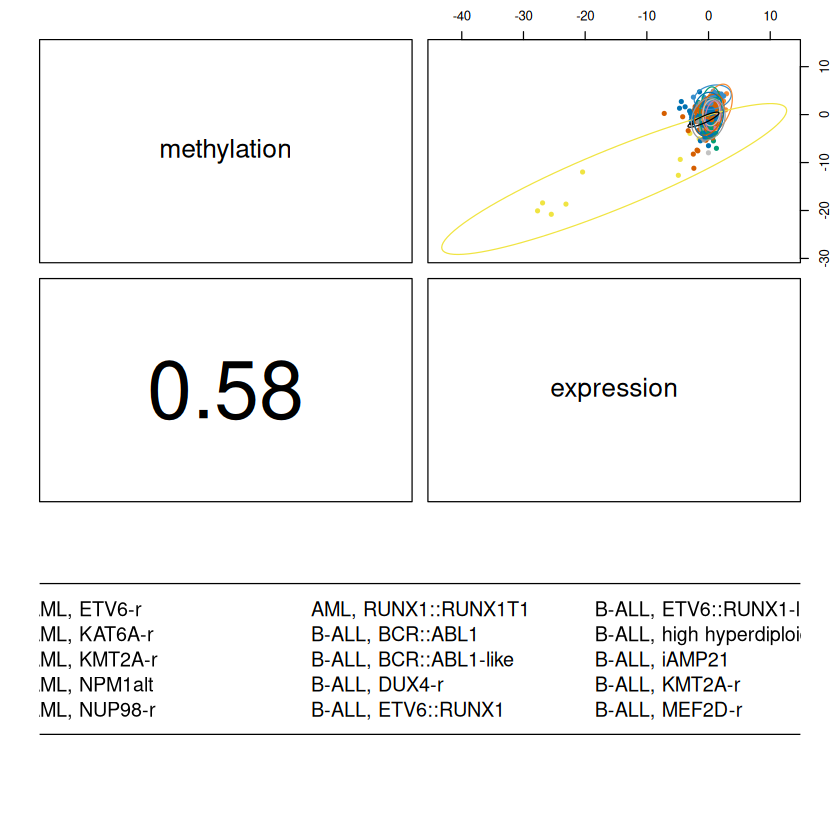

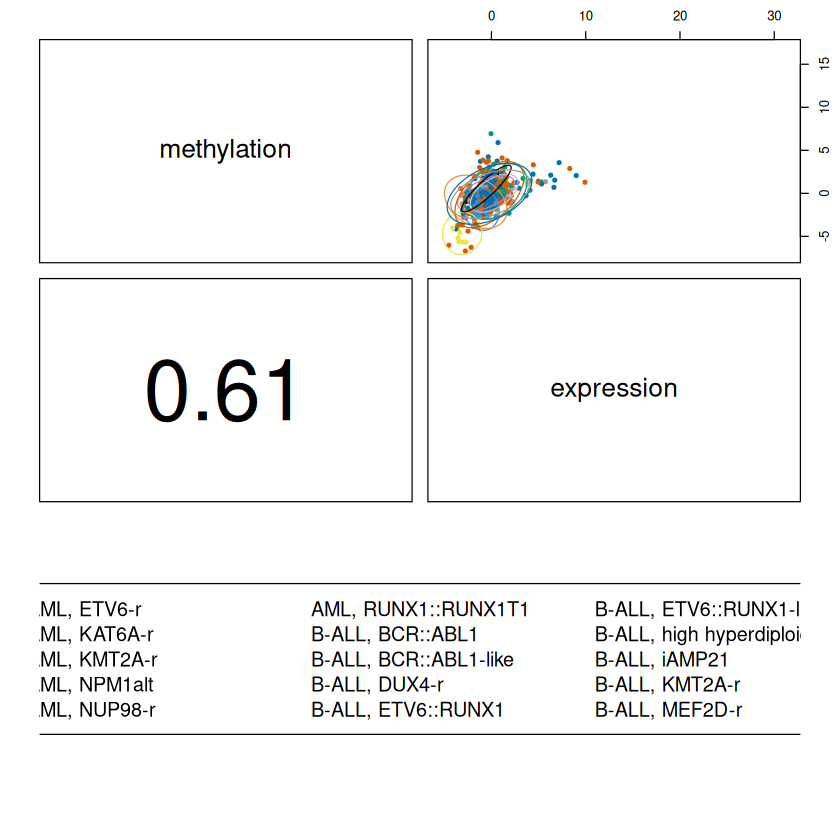

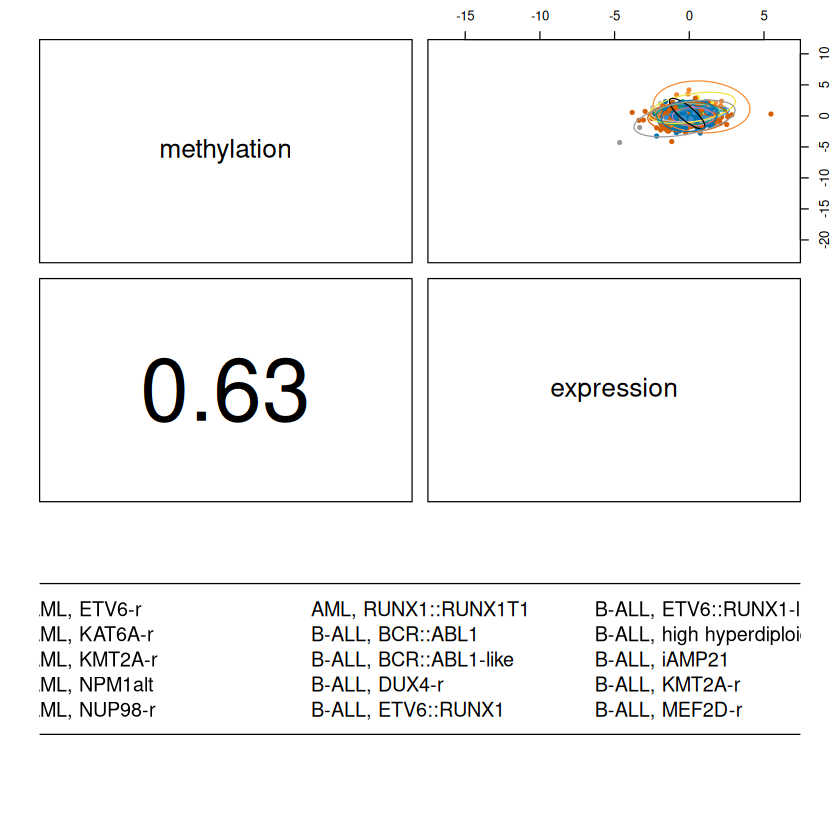

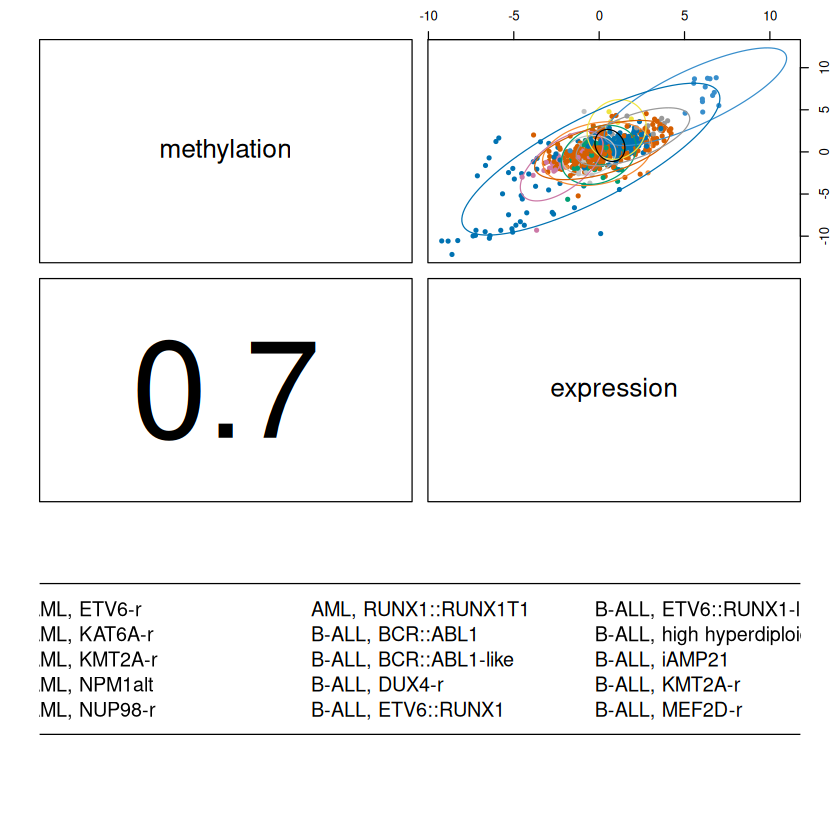

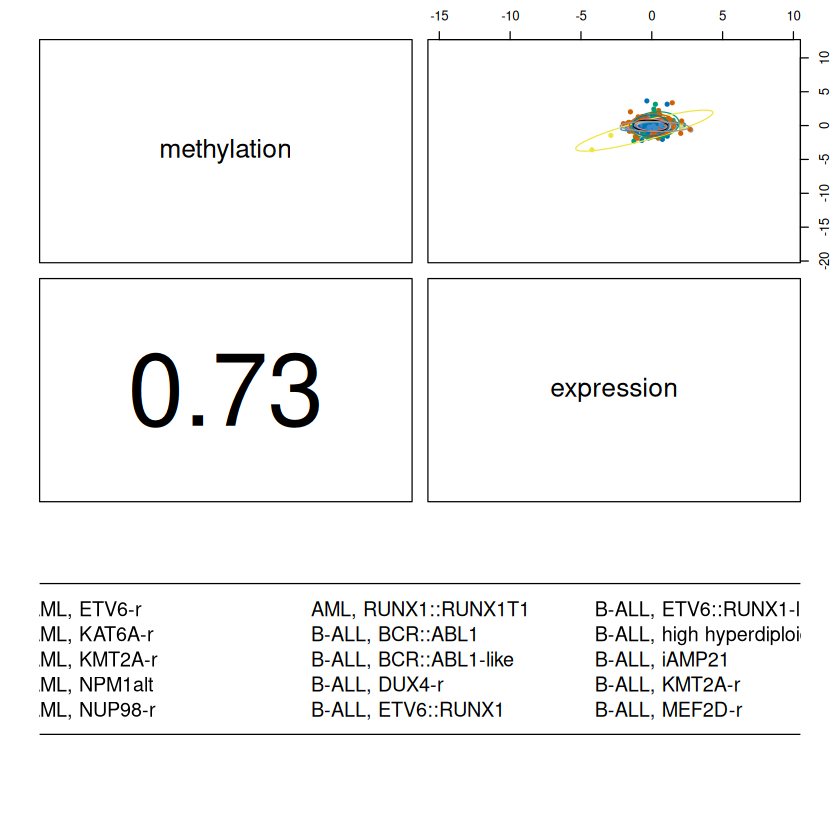

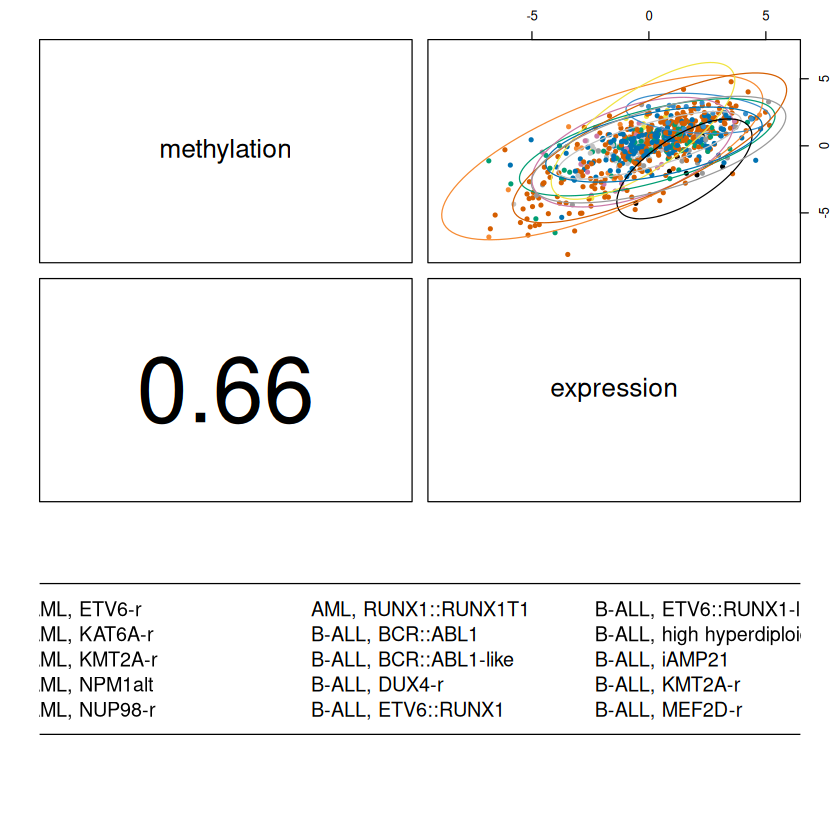

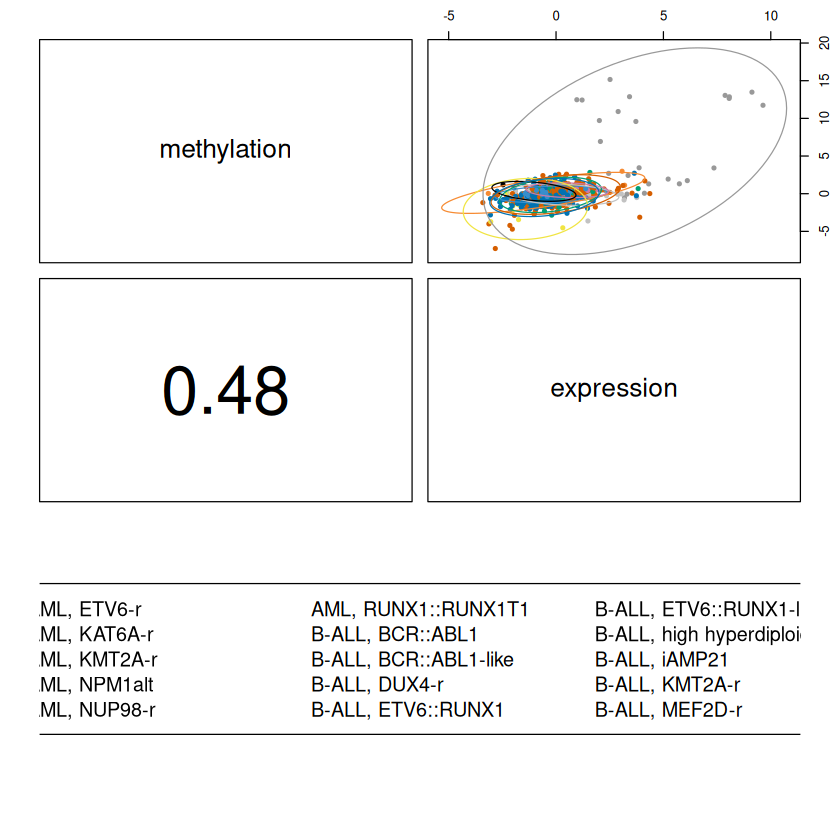

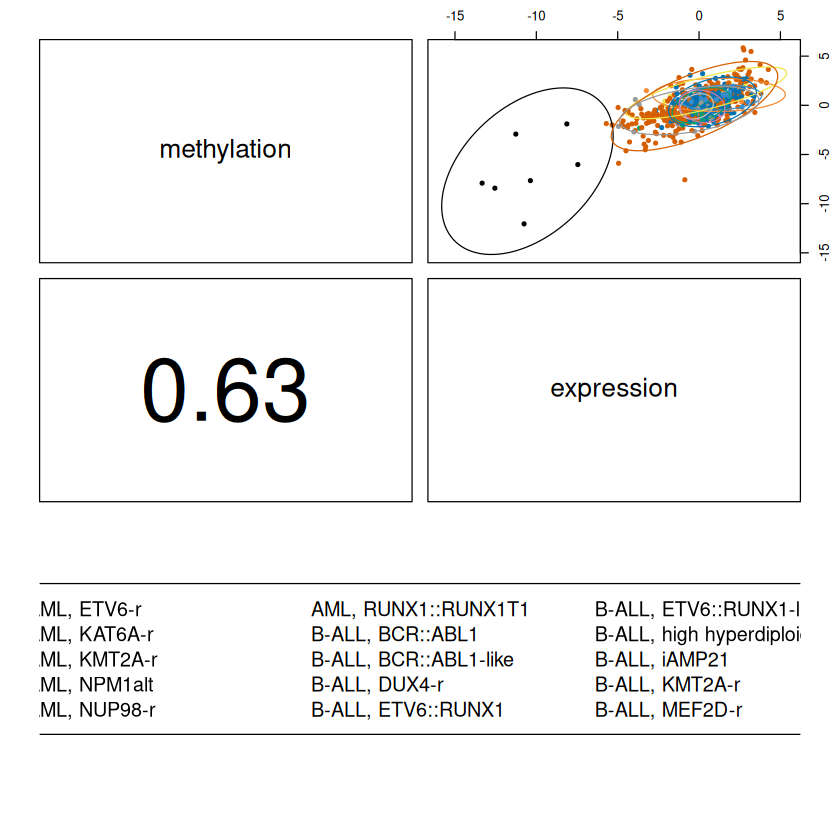

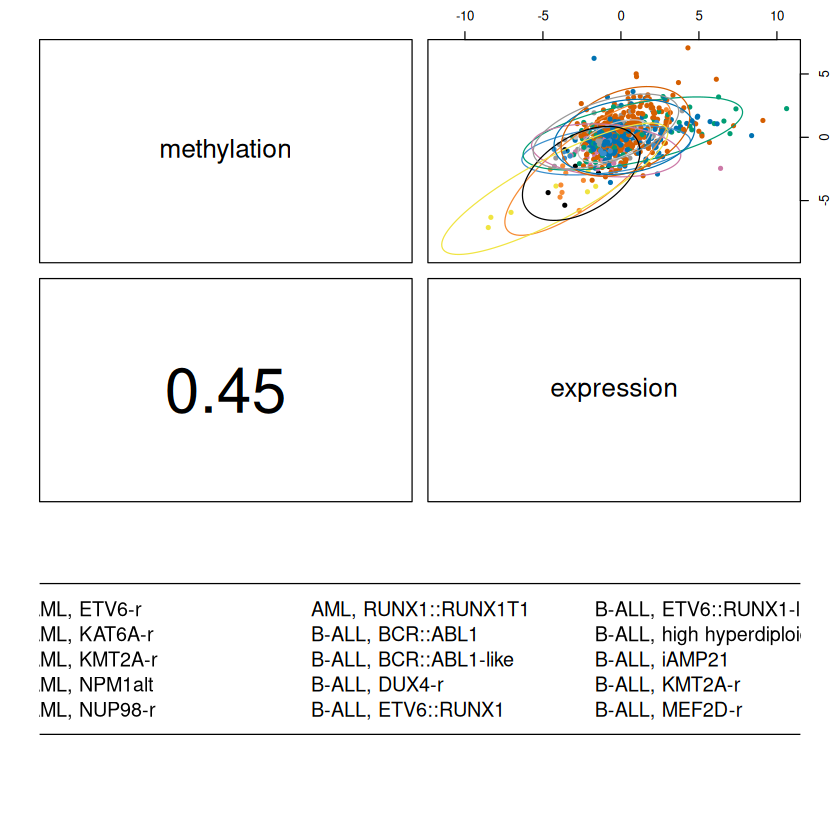

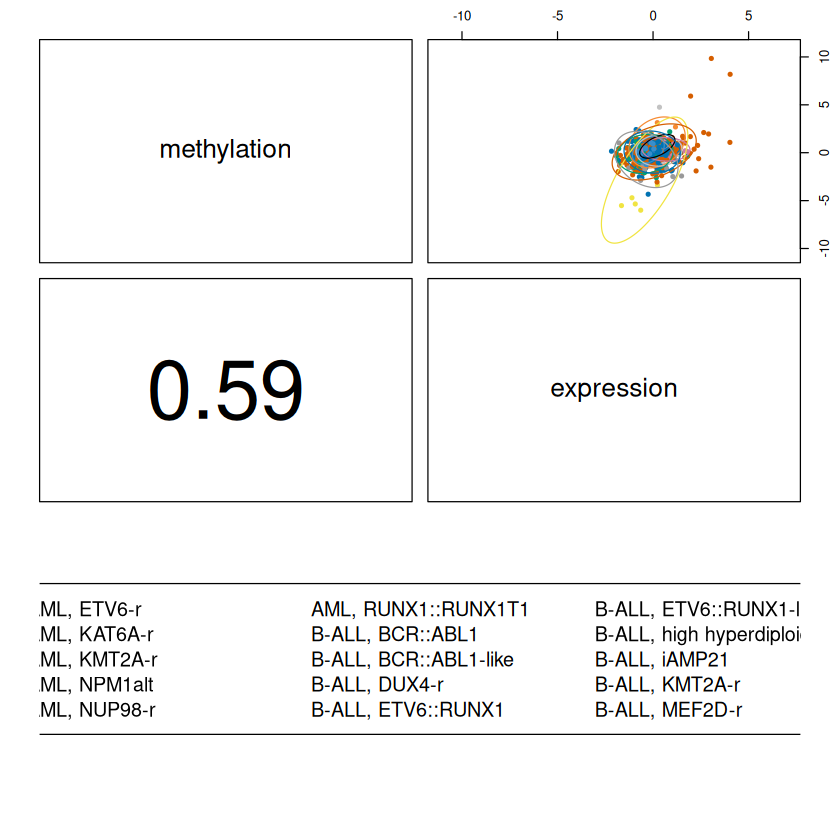

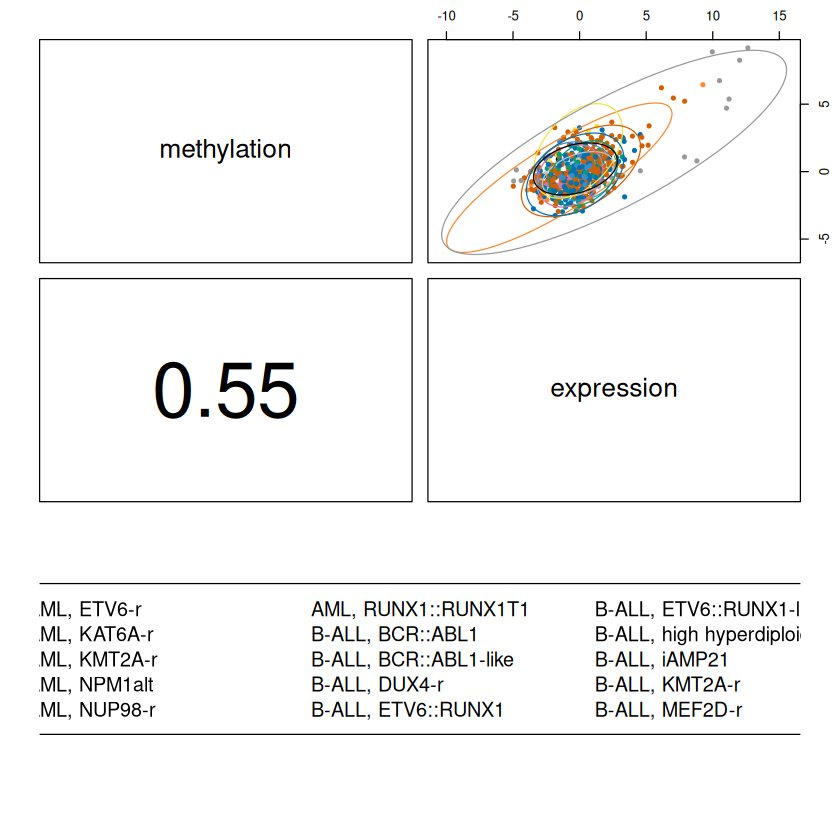

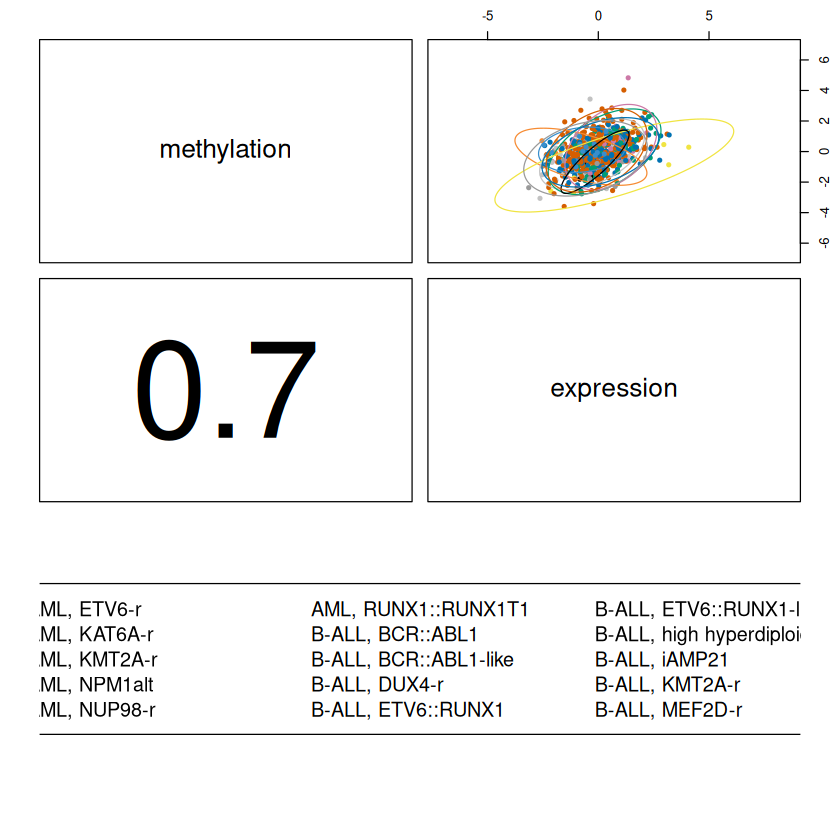

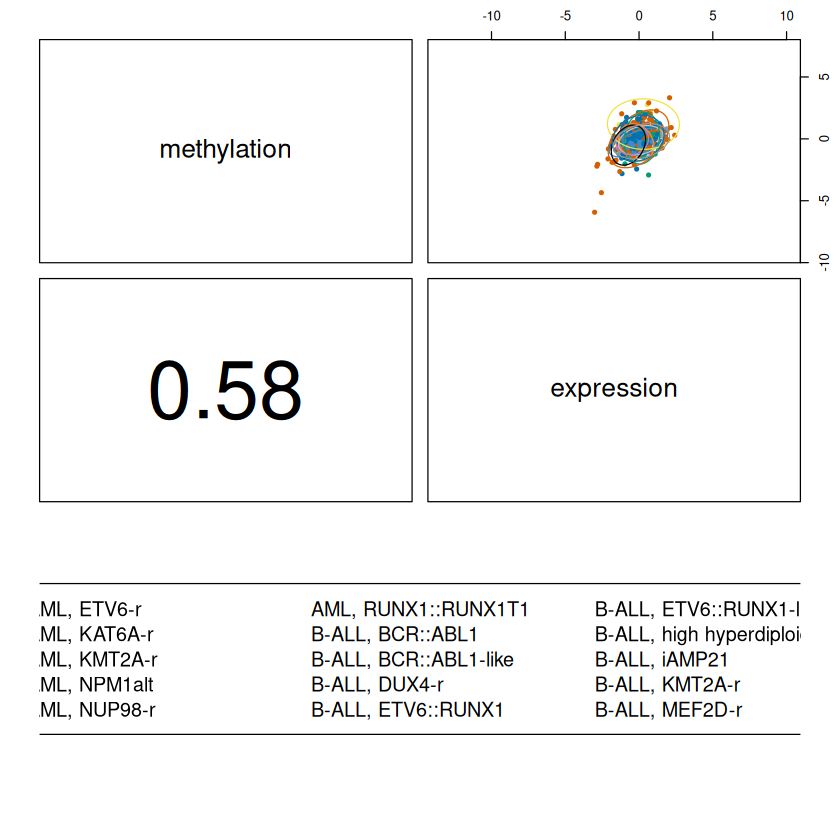

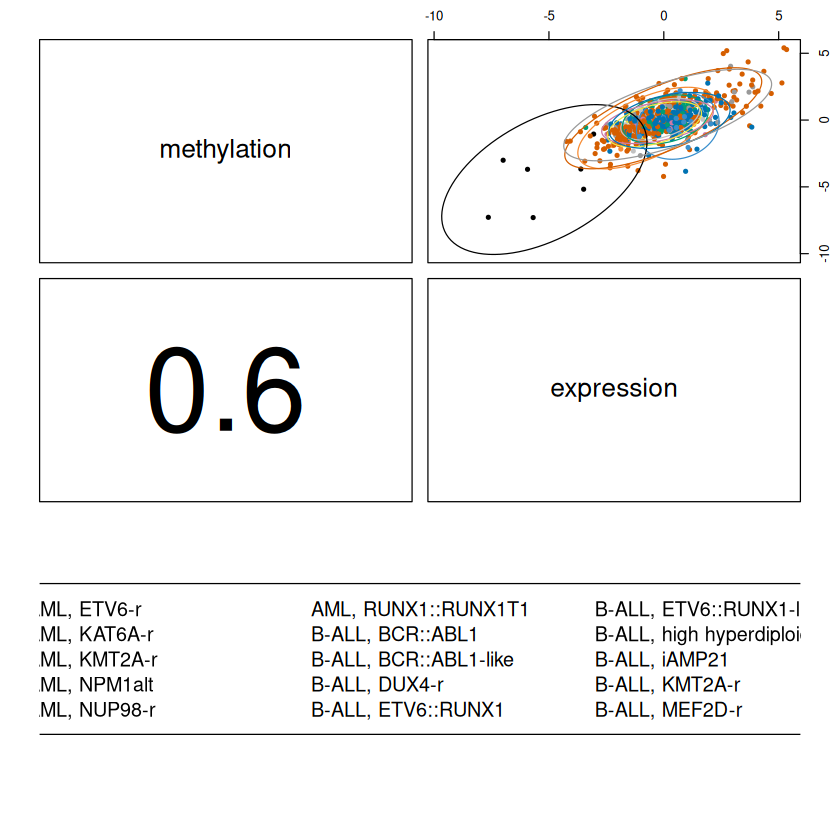

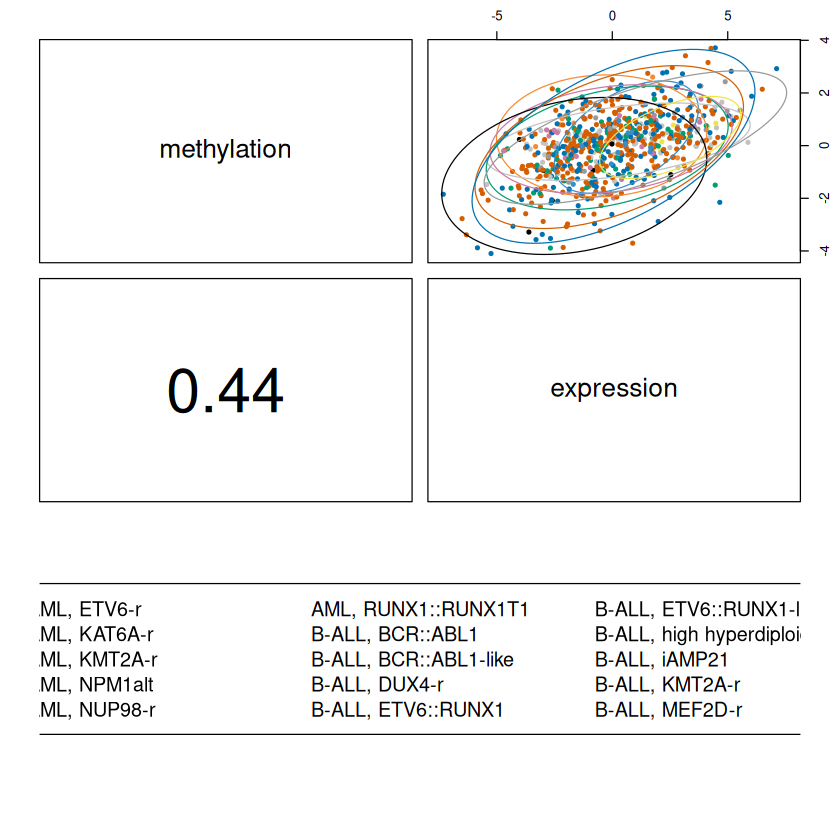

In [26]:
# ------------------------------------------------------------
# 6. Visualize correlation structure
# ------------------------------------------------------------

# Plot all components in a loop
for (comp in 1:NCOMP) {
    ## 6a. Component-level correlation between blocks
    plotDiablo(diablo.corr, ncomp = comp)
}


In [27]:
# # ensure names have no stray whitespace
# CLASS_COLORS$class <- trimws(CLASS_COLORS$class)

# # get classes in the order used by the model/plot
# classes <- levels(as.factor(Y))            # or levels(diablo.corr$Y)

# # build mapping and extract colors in that order
# color_map <- setNames(CLASS_COLORS$color, CLASS_COLORS$class)
# colors_for_plot <- color_map[classes]

# # fallback for unmatched classes
# colors_for_plot[is.na(colors_for_plot)] <- "#CCCCCC"

# # Filter for only the classes present in Y
# colors_for_plot <- colors_for_plot[classes %in% levels(Y)]

# colors_for_plot
# length(colors_for_plot)  # should match number of classes


In [28]:

# # use in circosPlot
# circosPlot(diablo.corr,
#            cutoff = 0.7,
#            comp = 1,
#            color.blocks = c('darkorchid', 'lightgreen'),
#            color.Y = colors_for_plot,
#            size.labels = 1.2,
#            size.variables = 0.6)

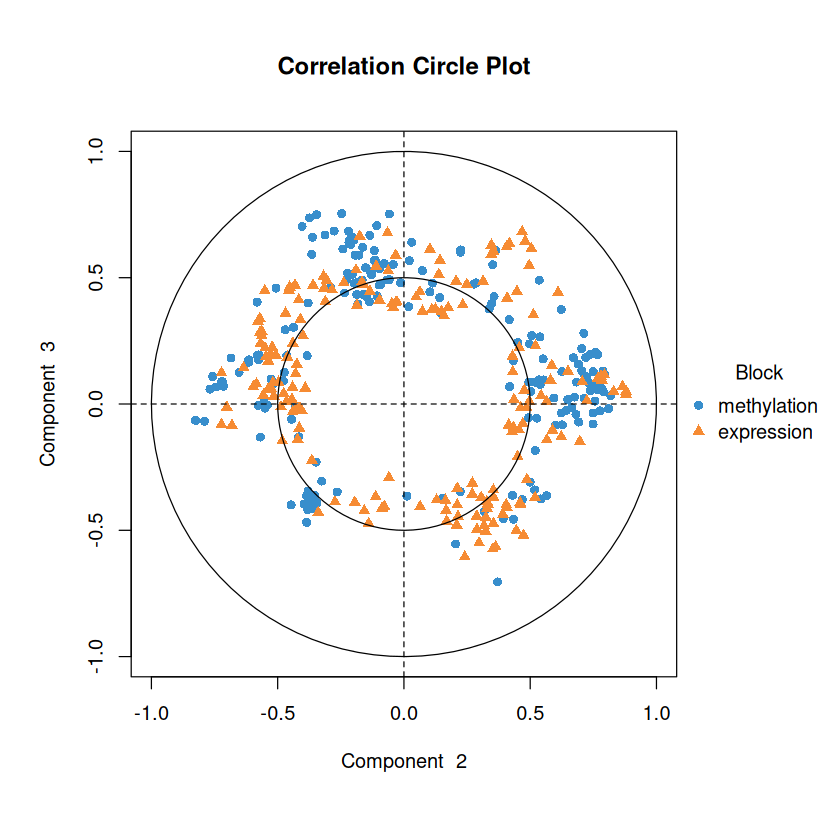

In [37]:
## 6c. Correlation circle plot — how variables from each block project together
plotVar(diablo.corr,
        style = 'graphics',
        legend = TRUE,
        pch = c(16, 17),
        cex = c(1, 1),
        comp = c(2, 3))



trimming values to [-3, 3] range for cim visualisation. See 'trim' arg in ?cimDiablo


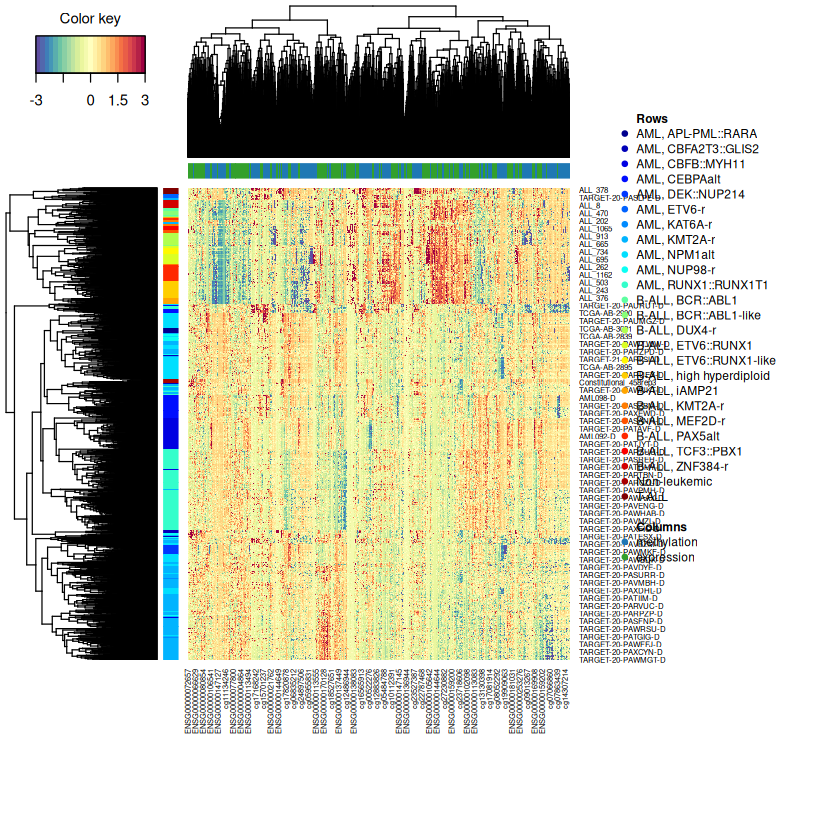

In [30]:

## 6d. Clustered heatmap of selected features across both blocks
cimDiablo(diablo.corr,
          margins = c(10, 15),
          size.legend = 0.6)


In [31]:

## 6e. Bipartite correlation network (exportable to Cytoscape)
network(diablo.corr,
        blocks = c(1, 2),
        cutoff = 0.7,
        color.node = c('darkorchid', 'lightgreen'),
        save = 'pdf', name.save = 'diablo_network')  # optional export


In [32]:

# ------------------------------------------------------------
# 7. Extract selected features and their correlations (for reporting)
# ------------------------------------------------------------
meth.vars <- selectVar(diablo.corr, block = 'methylation', comp = 1)$methylation
expr.vars <- selectVar(diablo.corr, block = 'expression', comp = 1)$expression

# example: pairwise correlation matrix between selected features
meth.selected <- X$methylation[, meth.vars$name]
expr.selected <- X$expression[, expr.vars$name]

corr.matrix <- cor(meth.selected, expr.selected)

# top correlated pairs (optional, for a supplementary table)
corr.df <- as.data.frame(as.table(corr.matrix))
colnames(corr.df) <- c("Methylation_Feature", "Expression_Feature", "Correlation")
corr.df <- corr.df[order(-abs(corr.df$Correlation)), ]
head(corr.df, 20)

,Methylation_Feature,Expression_Feature,Correlation
,<fct>,<fct>,<dbl>
201,cg03238899,ENSG00000144749,-0.8850657
301,cg03238899,ENSG00000196549,-0.8694339
101,cg03238899,ENSG00000270882,-0.8677931
501,cg03238899,ENSG00000162267,-0.8670587
7,cg24497541,ENSG00000015413,0.8661052
524,cg18121565,ENSG00000162267,-0.8648436
121,cg23324787,ENSG00000270882,-0.8647044
116,cg08457158,ENSG00000270882,-0.8626027
1,cg03238899,ENSG00000015413,-0.8624285
